# Market analysis of catering venues in Moscow

**Contents**

1. Goal
2. Analysis plan
3. Data overview
4. Data preprocessing (duplicates, missing values, new columns)
5. Data analysis (venue categories, seating, chains vs independents, districts, ratings, maps, streets, average bill)
6. Detailed study: opening a coffee shop
7. Recommendations

 <a id="goal"></a> 
 
 ## Goal

*Describe the Moscow food-service market to identify the most suitable location and format for a new venue.*

 <a id="research steps"></a> 

## Analysis plan

*Data overview*

*Data preprocessing*

*Data analysis*

*Detailed study: opening a coffee shop*

*Conclusions*

*Presentation*

In [1]:
# import the libraries needed for the analysis:
import pandas as pd
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt
from pandas.plotting import register_matplotlib_converters
import warnings
import scipy.stats as st
register_matplotlib_converters()
import os
import seaborn as sns
import math as mth
import plotly.express as px
from plotly import graph_objects as go
import re
import json
from folium import Map, Choropleth, Marker
from folium import Map
from folium.plugins import MarkerCluster
import plotly.express as px

 <a id="data review"></a> 

## Data overview

In [2]:
data = pd.read_csv('/datasets/moscow_places.csv')

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               8406 non-null   object 
 1   category           8406 non-null   object 
 2   address            8406 non-null   object 
 3   district           8406 non-null   object 
 4   hours              7870 non-null   object 
 5   lat                8406 non-null   float64
 6   lng                8406 non-null   float64
 7   rating             8406 non-null   float64
 8   price              3315 non-null   object 
 9   avg_bill           3816 non-null   object 
 10  middle_avg_bill    3149 non-null   float64
 11  middle_coffee_cup  535 non-null    float64
 12  chain              8406 non-null   int64  
 13  seats              4795 non-null   float64
dtypes: float64(6), int64(1), object(7)
memory usage: 919.5+ KB


 <a id="preprocessing"></a> 

## Data preprocessing

 <a id="duplicates"></a> 

### *Duplicates*

In [4]:
data.duplicated().sum()

0

*No exact duplicates found.*

 <a id="null"></a> 

### Missing values

In [5]:
data.isna().sum()

name                    0
category                0
address                 0
district                0
hours                 536
lat                     0
lng                     0
rating                  0
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
chain                   0
seats                3611
dtype: int64

In [6]:
# to decide how to handle missing values, compute the share (%) of missing values per column
pd.DataFrame(round(data.isna().mean()*100,1)).style.background_gradient('coolwarm')

,0
name,0.000000
category,0.000000
address,0.000000
district,0.000000
hours,6.400000
lat,0.000000
lng,0.000000
rating,0.000000
price,60.600000
avg_bill,54.600000


*Missing values were found in: hours, price, avg_bill, middle_avg_bill, middle_coffee_cup, seats.
The share of missing values is large (up to 93.6% in middle_coffee_cup), so dropping rows or imputing medians would not be appropriate.
The missing values were left as they are.*

 <a id="new columns"></a> 

### New columns

#### data['street']

In [7]:
# list of Russian words that denote a street type (street, lane, highway, avenue, square, etc.)
words = ['улица','ул','переулок','шоссе','проспект','площадь','проезд',
         'село','аллея','бульвар','набережная','тупик','линия']

# regular expression to extract the words listed in `words`
str_pat = r".*,\s*\b([^,]*?(?:{})\b[^,]*)[,$]+".format("|".join(words))

# new column with the street name
data['street'] = data["address"].str.extract(str_pat, flags=re.I)

#### data['is_24/7']

In [8]:
data['is_24/7'] = data['hours'].str.contains('руглосуточно')

In [9]:
# lower-case the venue names
data['name'] = data['name'].str.lower()

In [10]:
# find duplicates with the same venue name and address
data.duplicated(subset=['name', 'address'], keep='first').sum()

3

In [11]:
# drop the duplicates
data = data.drop_duplicates(subset=['name', 'address'])

In [12]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 8403 entries, 0 to 8405
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               8403 non-null   object 
 1   category           8403 non-null   object 
 2   address            8403 non-null   object 
 3   district           8403 non-null   object 
 4   hours              7868 non-null   object 
 5   lat                8403 non-null   float64
 6   lng                8403 non-null   float64
 7   rating             8403 non-null   float64
 8   price              3315 non-null   object 
 9   avg_bill           3816 non-null   object 
 10  middle_avg_bill    3149 non-null   float64
 11  middle_coffee_cup  535 non-null    float64
 12  chain              8403 non-null   int64  
 13  seats              4792 non-null   float64
 14  street             8173 non-null   object 
 15  is_24/7            7868 non-null   object 
dtypes: float64(6), int64(1),

 <a id="data analysis"></a> 

## Data analysis

### Number of venues by category

In [13]:
data['category'].unique()

array(['кафе', 'ресторан', 'кофейня', 'пиццерия', 'бар,паб',
       'быстрое питание', 'булочная', 'столовая'], dtype=object)

*Categories in the data: cafe, restaurant, coffee shop, pizzeria, bar/pub, fast food, bakery, canteen.*

In [14]:
# pivot table: unique addresses per venue category
data_count_by_category = data.pivot_table(index='category', values=['address'], aggfunc='nunique').sort_values(by=['address'],ascending=False)
# rename columns for plotting
data_count_by_category.reset_index(inplace= True )
data_count_by_category.rename(columns = {'address':'count'}, inplace = True )
data_count_by_category

,category,count
0,кафе,2045
1,ресторан,1697
2,кофейня,1215
3,"бар,паб",707
4,пиццерия,602
5,быстрое питание,489
6,столовая,303
7,булочная,249


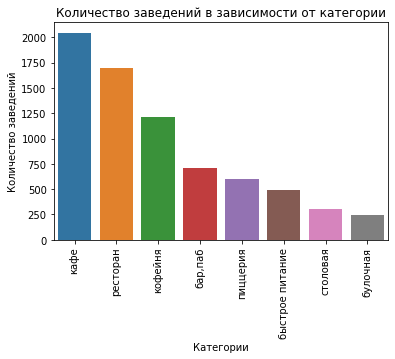

In [15]:
# bar chart
ax = sns.barplot(x='category', y='count', data=data_count_by_category)
plt.title ('Number of venues by category')
plt.ylabel ('Number of venues')
plt.xlabel ('Category')
plt.xticks(rotation=90);

*The largest categories are cafe, restaurant and coffee shop.*

*The smallest are bakery and canteen.*

### Seating capacity by venue category

In [16]:
# pivot table: median number of seats per venue category
data_seats_by_category = data.pivot_table(index='category', values=['seats'], aggfunc='median').sort_values(by=['seats'],ascending=False)
# rename columns for plotting
data_seats_by_category.reset_index(inplace= True )
data_seats_by_category.rename(columns = {'seats':'median_seats'}, inplace = True )

In [17]:
data_seats_by_category

,category,median_seats
0,ресторан,86.0
1,"бар,паб",82.0
2,кофейня,80.0
3,столовая,75.5
4,быстрое питание,65.0
5,кафе,60.0
6,пиццерия,55.0
7,булочная,50.0


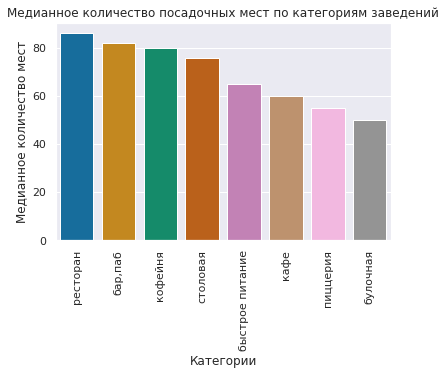

In [18]:
# bar chart
sns.set_theme(palette="colorblind")
ax = sns.barplot(x='category', y='median_seats', data=data_seats_by_category)
plt.title ('Median number of seats by venue category')
plt.ylabel ('Median number of seats')
plt.xlabel ('Category')
plt.xticks(rotation=90);

*Restaurants, bars/pubs and coffee shops have the most seats.*

*Pizzerias and bakeries have the fewest.*

*Seating capacity most likely reflects how long guests stay.*

*Pizza is usually ordered for delivery; pastries are eaten quickly or taken away.*

*In restaurants, bars and coffee shops guests tend to stay longer.*

*Rent, interior and related costs are therefore likely to be lower for a pizzeria or bakery.*

### Chain vs independent venues

In [19]:
# pivot table: unique addresses for chain and independent venues
data_chains = data.pivot_table(index='chain', values=['address'], aggfunc='nunique').sort_values(by=['address'],ascending=False)
data_chains.reset_index(inplace= True )
data_chains.rename(columns = {'address':'place_count'}, inplace = True )
data_chains['part'] = data_chains['place_count']/ sum (data_chains['place_count'])

In [20]:
data_chains

,chain,place_count,part
0,0,4046,0.624094
1,1,2437,0.375906


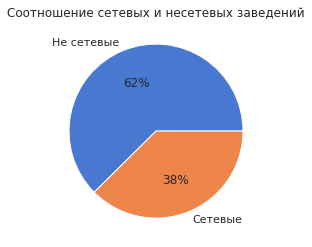

In [21]:
sns.set_theme(palette="muted")
plt.title ('Chain vs independent venues')
labels = ['Independent', 'Chain']
plt.pie(data_chains['place_count'], labels=labels, autopct = '%0.0f%%')
plt.show()

*There are more independent venues than chain venues.*

### Unique addresses by category and chain membership

In [22]:
# pivot table: unique addresses by venue category and chain membership
data_chains_by_category = pd.pivot_table(data, values=['address'], index=['category'], columns=['chain'], aggfunc='nunique')
data_chains_by_category = data_chains_by_category.rename(columns = {'address':'place_count'}).reset_index()
data_chains_by_category = data_chains_by_category.sort_values(by = [('place_count',  0)], ascending = False)

In [23]:
# share of chain venues in the total
data_chains_by_category['chain_part'] = data_chains_by_category[('place_count',  1)]/(data_chains_by_category[('place_count',  1)] + data_chains_by_category[('place_count',  0)])
data_chains_by_category

category place_count      chain_part
chain                            0    1           
3                 кафе        1435  721   0.334416
6             ресторан        1165  640   0.354571
4              кофейня         657  616   0.483896
0              бар,паб         563  166   0.227709
2      быстрое питание         322  209   0.393597
5             пиццерия         291  319   0.522951
7             столовая         220   86   0.281046
1             булочная          98  156   0.614173

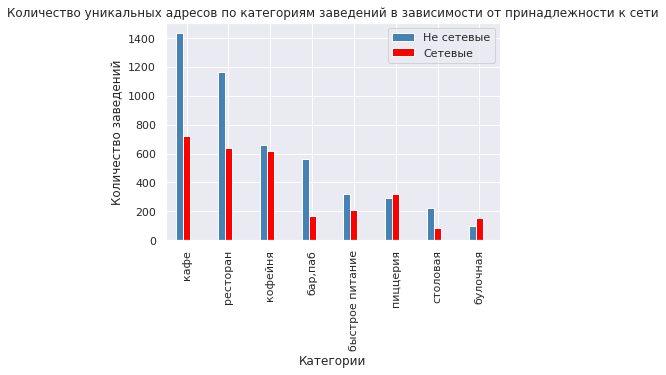

In [24]:
# plot the result
data_chains_by_category.set_index('category').plot(kind='bar', color=['steelblue', 'red'])
plt.title ('Unique addresses by venue category and chain membership')
plt.ylabel ('Number of venues')
plt.xlabel ('Category')
plt.xticks(rotation=90)
plt.legend(['Independent', 'Chain']);

*Independent venues are more common, except for pizzerias and bakeries (mostly chains) and coffee shops (roughly equal numbers of chain and independent venues).*

### Top 15 chains in Moscow

In [25]:
# pivot table: unique addresses per chain
popular_chains = pd.pivot_table(data, values=['address'], index=['name', 'category','chain'], aggfunc='nunique').sort_values(by = 'address', ascending = False)
popular_chains = popular_chains.query('chain==1')
popular_chains = popular_chains.reset_index()
display (popular_chains.head(15))

,name,category,chain,address
0,шоколадница,кофейня,1,119
1,домино'с пицца,пиццерия,1,76
2,додо пицца,пиццерия,1,74
3,one price coffee,кофейня,1,71
4,яндекс лавка,ресторан,1,69
5,cofix,кофейня,1,65
6,prime,ресторан,1,49
7,кофепорт,кофейня,1,42
8,кулинарная лавка братьев караваевых,кафе,1,39
9,теремок,ресторан,1,36


*Among chains, coffee shops and pizzerias are the most common categories.*

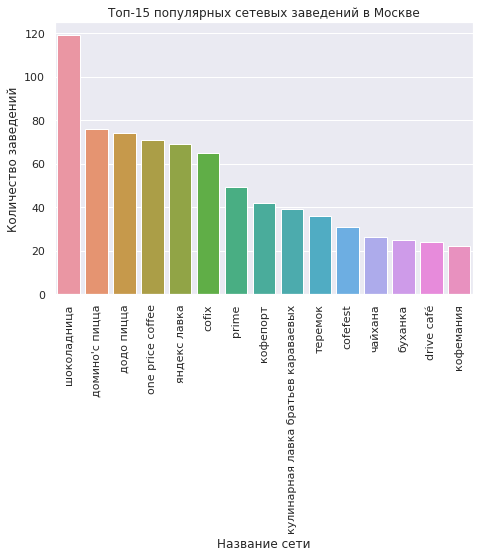

In [26]:
# plot the result
plt.figure(figsize=(7.5, 5))
popular_chains_top_15 = popular_chains.head(15)
ax = sns.barplot(x='name', y='address', data = popular_chains_top_15)
plt.title ('Top 15 chains in Moscow')
plt.ylabel ('Number of venues')
plt.xlabel ('Chain')
plt.xticks(rotation=90);

*The largest chain is Shokoladnitsa (a coffee-shop chain).*

### Number of venues by category and administrative district

In [27]:
# pivot table: unique addresses by administrative district and category
places_by_districts_and_category = pd.pivot_table(data, values=['address'], index=['category', 'district'], aggfunc='nunique').sort_values(by = 'address', ascending = False)
places_by_districts_and_category.reset_index(inplace= True )
places_by_districts_and_category

,category,district,address
0,ресторан,Центральный административный округ,580
1,кафе,Центральный административный округ,412
2,кофейня,Центральный административный округ,389
3,"бар,паб",Центральный административный округ,332
4,кафе,Северо-Восточный административный округ,236
...,...,...,...
67,"бар,паб",Северо-Западный административный округ,22
68,столовая,Северо-Западный административный округ,17
69,столовая,Юго-Западный административный округ,16
70,булочная,Северо-Западный административный округ,12


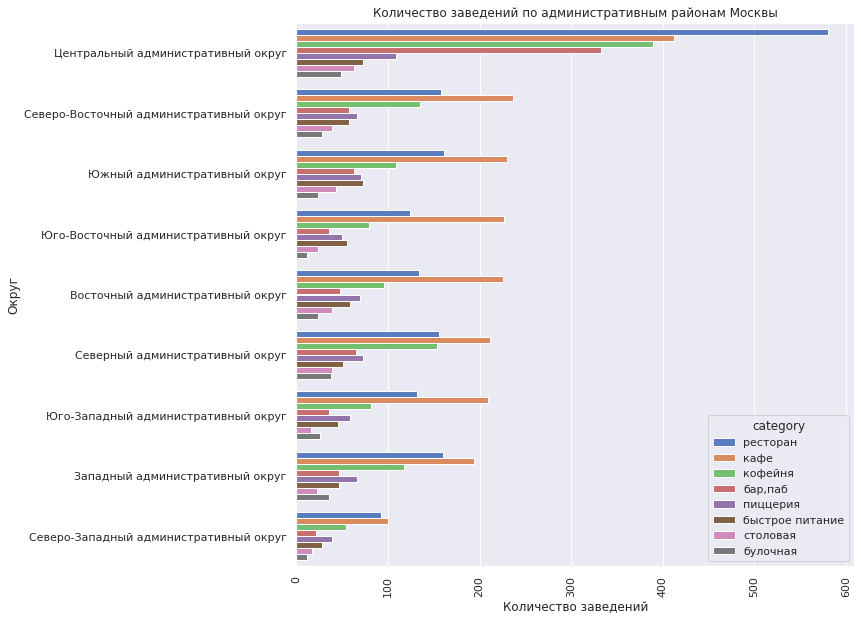

In [28]:
# plot the result
plt.figure(figsize=(10, 10))
ax = sns.barplot(x='address', y='district', hue='category', data=places_by_districts_and_category, orient='h')
plt.title ('Number of venues by administrative district of Moscow')
plt.ylabel ('District')
plt.xlabel ('Number of venues')
plt.xticks(rotation=90);

*Cafes are the largest category in every district except the Central district, where restaurants lead. In all districts without exception the top 3 categories are cafe, coffee shop and restaurant.*

### Average rating by venue category

In [29]:
# pivot table: average rating by venue category
rating_by_category = pd.pivot_table(data, values=['rating'], index=['category'], aggfunc='mean').sort_values(by = 'rating', ascending = False)
rating_by_category.reset_index(inplace= True )
rating_by_category

,category,rating
0,"бар,паб",4.387696
1,пиццерия,4.301264
2,ресторан,4.290402
3,кофейня,4.277282
4,булочная,4.268359
5,столовая,4.211429
6,кафе,4.123896
7,быстрое питание,4.050249


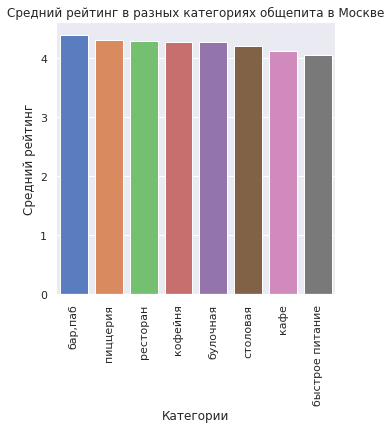

In [30]:
# plot the result
plt.figure(figsize=(5, 5))
ax = sns.barplot(x='category', y='rating', data = rating_by_category)
plt.title ('Average rating by venue category in Moscow')
plt.ylabel ('Average rating')
plt.xlabel ('Category')
plt.xticks(rotation=90);

*Average ratings differ little between categories.*

### Average venue rating by district

In [60]:
# table with average venue ratings
rating_by_district = data.groupby('district', as_index=False)['rating'].agg('mean')
rating_by_district

,district,rating
0,Восточный административный округ,4.174185
1,Западный административный округ,4.181647
2,Северный административный округ,4.239822
3,Северо-Восточный административный округ,4.147978
4,Северо-Западный административный округ,4.208802
5,Центральный административный округ,4.377520
6,Юго-Восточный административный округ,4.101120
7,Юго-Западный административный округ,4.172920
8,Южный административный округ,4.184417


In [61]:
# load the GeoJSON file with Moscow district boundaries
state_geo = '/datasets/admin_level_geomap.geojson'
# moscow_lat, moscow_lng: coordinates of the city center
moscow_lat, moscow_lng = 55.751244, 37.618423

# create the map of Moscow
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)

# build a choropleth with the Choropleth constructor and add it to the map
Choropleth(
    geo_data=state_geo,
    data=rating_by_district,
    columns=['district', 'rating'],
    key_on='feature.name',
    fill_color='YlGn',
    fill_opacity=0.8,
    legend_name='Average venue rating by district',
).add_to(m)

# show the map
m

Venues in the Central district have the highest ratings; ratings in the North-West are also higher than in the Southern and South-Eastern districts.

### All venues on the map

In [62]:
# moscow_lat, moscow_lng: coordinates of the city center
moscow_lat, moscow_lng = 55.751244, 37.618423

# create the map of Moscow
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)
# create an empty marker cluster and add it to the map
marker_cluster = MarkerCluster().add_to(m)

# function that takes a dataframe row,
# creates a marker at that point and adds it to marker_cluster
def create_clusters(row):
    Marker(
        [row['lat'], row['lng']],
        popup=f"{row['name']} {row['rating']}",
    ).add_to(marker_cluster)

# apply create_clusters() to every row of the dataframe
data.apply(create_clusters, axis=1)

# show the map
m

### Top 15 streets by number of venues

In [63]:
# Top 15 streets by venue count
popular_street = pd.pivot_table(data, values=['address'], index=['street'], aggfunc='nunique').sort_values(by = 'address', ascending = False)
popular_street.reset_index(inplace = True)
top15_street = popular_street.head(15)
top15_street

,street,address
0,проспект Мира,103
1,Ленинский проспект,67
2,Ленинградский проспект,63
3,Дмитровское шоссе,55
4,Профсоюзная улица,55
5,Варшавское шоссе,47
6,проспект Вернадского,40
7,Каширское шоссе,40
8,Люблинская улица,36
9,Ленинградское шоссе,36


In [64]:
# List of the 15 most popular streets
street_list = top15_street['street']. tolist ()
street_list

['проспект Мира',
 'Ленинский проспект',
 'Ленинградский проспект',
 'Дмитровское шоссе',
 'Профсоюзная улица',
 'Варшавское шоссе',
 'проспект Вернадского',
 'Каширское шоссе',
 'Люблинская улица',
 'Ленинградское шоссе',
 'Пятницкая улица',
 'Волгоградский проспект',
 'Кутузовский проспект',
 'Алтуфьевское шоссе',
 'улица Арбат']

In [65]:
# Slice the dataframe to the 15 most popular streets
top_street_by_category_slice = data.query("street in ['проспект Мира', 'Ленинский проспект','Ленинградский проспект','Дмитровское шоссе','Профсоюзная улица','Варшавское шоссе','проспект Вернадского','Каширское шоссе','Люблинская улица','Ленинградское шоссе','Пятницкая улица','Волгоградский проспект','Кутузовский проспект','Алтуфьевское шоссе','улица Арбат']")
top_street_by_category_slice

,name,category,address,district,hours,lat,lng,rating,price,avg_bill,middle_avg_bill,middle_coffee_cup,chain,seats,street,is_24/7
8,donna maria,ресторан,"Москва, Дмитровское шоссе, 107, корп. 4",Северный административный округ,"ежедневно, 10:00–22:00",55.880045,37.539006,4.8,средние,Средний счёт:от 500 ₽,500.0,NaN,0,79.0,Дмитровское шоссе,False
17,чайхана беш-бармак,ресторан,"Москва, Ленинградское шоссе, 71Б, стр. 2",Северный административный округ,"ежедневно, круглосуточно",55.876908,37.449876,4.4,средние,Средний счёт:350–500 ₽,425.0,NaN,0,96.0,Ленинградское шоссе,True
26,пикочино,пиццерия,"Москва, Дмитровское шоссе, 107к2",Северный административный округ,"пн-чт 11:00–22:00; пт,сб 11:00–23:00; вс 11:00...",55.879390,37.541228,4.5,средние,Средний счёт:300–1500 ₽,900.0,NaN,0,NaN,Дмитровское шоссе,False
29,кушай город,столовая,"Москва, Дмитровское шоссе, 157, стр. 15",Северный административный округ,пн-пт 09:00–16:00,55.898414,37.539256,4.2,средние,Средний счёт:200–250 ₽,225.0,NaN,1,NaN,Дмитровское шоссе,False
43,суши & пицца,ресторан,"Москва, Дмитровское шоссе, 169, корп. 6",Северо-Восточный административный округ,"ежедневно, 10:00–23:00",55.928943,37.540548,4.0,NaN,NaN,NaN,NaN,0,NaN,Дмитровское шоссе,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8377,автосервис у рустама,кафе,"Москва, Волгоградский проспект, 177, стр. 1",Юго-Восточный административный округ,"ежедневно, круглосуточно",55.701764,37.796410,3.1,NaN,NaN,NaN,NaN,0,206.0,Волгоградский проспект,True
8396,пекинский двор,ресторан,"Москва, Ленинский проспект, 158",Западный административный округ,"ежедневно, 11:00–23:00",55.651706,37.482667,4.3,выше среднего,Средний счёт:1000–1500 ₽,1250.0,NaN,0,200.0,Ленинский проспект,False
8401,суши мания,кафе,"Москва, Профсоюзная улица, 56",Юго-Западный административный округ,"ежедневно, 09:00–02:00",55.670021,37.552480,4.4,NaN,NaN,NaN,NaN,0,86.0,Профсоюзная улица,False
8403,самовар,кафе,"Москва, Люблинская улица, 112А, стр. 1",Юго-Восточный административный округ,"ежедневно, круглосуточно",55.648859,37.743219,3.9,NaN,Средний счёт:от 150 ₽,150.0,NaN,0,150.0,Люблинская улица,True


In [66]:
# Pivot table: venues of each category on the 15 most popular streets
popular_street_by_category = pd.pivot_table(top_street_by_category_slice, values=['address'], index=['street', 'category'], aggfunc='nunique').sort_values(by = 'address', ascending = False)
popular_street_by_category.reset_index(inplace = True)

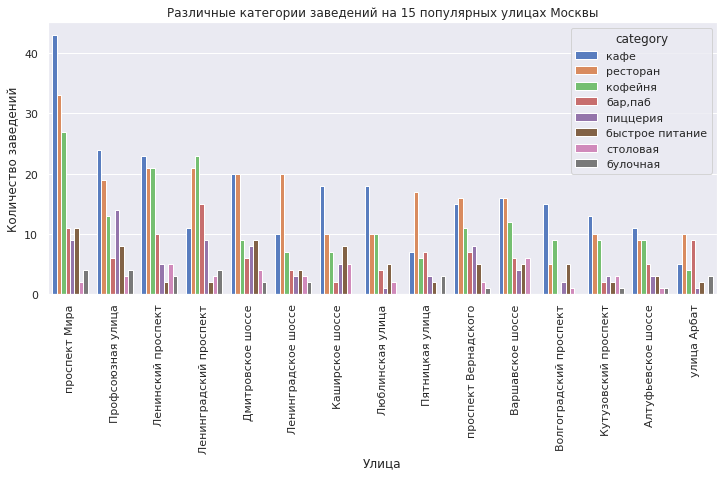

In [67]:
# Plot the result
plt.figure(figsize=(12, 5))
ax = sns.barplot(x='street', y='address', hue='category', data=popular_street_by_category)
plt.title ('Venue categories on the 15 most popular streets of Moscow')
plt.ylabel ('Number of venues')
plt.xlabel ('Street')
plt.xticks(rotation=90);

The category mix on popular streets resembles the mix by district. Cafe, restaurant and coffee shop are the most common, with a few exceptions:
- on Profsoyuznaya Street pizzerias outnumber coffee shops
- on Leningradsky Avenue and the Arbat bars outnumber cafes
- on Kashirskoye Highway fast food is more common than coffee shops


### Streets with a single venue

In [68]:
# streets with only 1 venue
not_popular_street = popular_street.query("address == 1")

In [69]:
# list of streets with a single venue
not_popular_street_list = not_popular_street['street'].tolist ()

In [70]:
# Slice the dataframe to the low-traffic streets
not_popular_street_by_category_slice = data.query("street in @not_popular_street_list")

In [71]:
# Pivot table: which categories are most common on low-traffic streets
nottop = pd.pivot_table(not_popular_street_by_category_slice, values=['street'], index=['category'], aggfunc='nunique').sort_values(by='street', ascending = False)
nottop.reset_index(inplace=True)

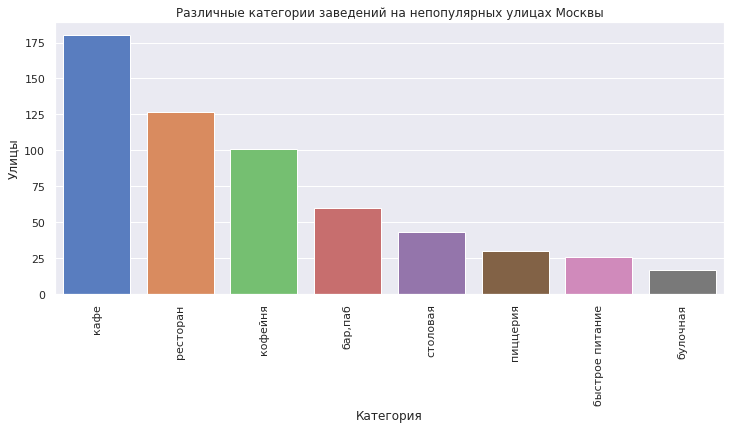

In [72]:
# Plot the result
plt.figure(figsize=(12, 5))
ax = sns.barplot(x='category', y='street', data = nottop)
plt.title ('Venue categories on low-traffic streets of Moscow')
plt.ylabel ('Streets')
plt.xlabel ('Category')
plt.xticks(rotation=90);

Cafes are the most common venue type on low-traffic streets; bakeries are the least common.

### Average bill by district

In [73]:
median_bill = pd.pivot_table(data, values=['middle_avg_bill'], index=['district'], aggfunc='median').sort_values(by='middle_avg_bill', ascending = False)
median_bill.reset_index(inplace=True)

In [74]:
median_bill

,district,middle_avg_bill
0,Западный административный округ,1000.0
1,Центральный административный округ,1000.0
2,Северо-Западный административный округ,700.0
3,Северный административный округ,650.0
4,Юго-Западный административный округ,600.0
5,Восточный административный округ,575.0
6,Северо-Восточный административный округ,500.0
7,Южный административный округ,500.0
8,Юго-Восточный административный округ,450.0


In [75]:
# moscow_lat, moscow_lng: coordinates of the city center
moscow_lat, moscow_lng = 55.751244, 37.618423

# create the map of Moscow
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)

# build a choropleth with the Choropleth constructor and add it to the map
Choropleth(
    geo_data=state_geo,
    data= median_bill,
    columns=['district', 'middle_avg_bill'],
    key_on='feature.name',
    fill_color='YlGn',
    fill_opacity=0.8,
    legend_name='Median average bill by district',
).add_to(m)

# show the map
m

In the Central and Western districts the median average bill is much higher than elsewhere. The lowest median is in the South-Eastern district.

The Northern districts also have a higher median bill than the Southern ones.

### Summary of the data analysis

- By venue category:

Cafes, restaurants and coffee shops are the largest categories.

Bakeries and canteens are the smallest.

Seating capacity depends on category: restaurants, bars/pubs and coffee shops have the most seats; pizzerias and bakeries the fewest.

Independent venues are more common, except for pizzerias and bakeries (mostly chains) and coffee shops (roughly equal split).

Cafes lead in every district except the Central district, where restaurants lead. In all districts the top 3 are cafe, coffee shop and restaurant.

Average ratings differ little between categories.


- By location:
Venues in the Central district have the highest ratings; the North-West also rates higher than the Southern and South-Eastern districts.

The category mix on popular streets resembles the mix by district, with a few exceptions:

on Profsoyuznaya Street pizzerias outnumber coffee shops

on Leningradsky Avenue and the Arbat bars outnumber cafes

on Kashirskoye Highway fast food is more common than coffee shops

Cafes are the most common venue type on low-traffic streets; bakeries the least common.

In the Central and Western districts the median average bill is much higher than elsewhere; the lowest is in the South-East.

The Northern districts have a higher median bill than the Southern ones.


## Detailed study: opening a coffee shop

### Number and location of coffee shops by district

In [76]:
# slice the data to the 'coffee shop' category
coffee_place = data.query("category == 'кофейня'")
coffee_place.count()

name                 1413
category             1413
address              1413
district             1413
hours                1398
lat                  1413
lng                  1413
rating               1413
price                 476
avg_bill              721
middle_avg_bill       200
middle_coffee_cup     521
chain                1413
seats                 751
street               1378
is_24/7              1398
dtype: int64

The dataset contains 1,413 coffee shops.

In [77]:
# pivot table: coffee shops per district
coffee_place_by_district = pd.pivot_table(coffee_place, values=['address'], index=['district'], aggfunc='nunique').sort_values(by='address', ascending = False)
coffee_place_by_district.reset_index(inplace=True)

In [78]:
coffee_place_by_district

,district,address
0,Центральный административный округ,389
1,Северный административный округ,154
2,Северо-Восточный административный округ,135
3,Западный административный округ,117
4,Южный административный округ,109
5,Восточный административный округ,96
6,Юго-Западный административный округ,82
7,Юго-Восточный административный округ,79
8,Северо-Западный административный округ,54


In [79]:
# moscow_lat, moscow_lng: coordinates of the city center
moscow_lat, moscow_lng = 55.751244, 37.618423

# create the map of Moscow
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)

# build a choropleth with the Choropleth constructor and add it to the map
Choropleth(
    geo_data=state_geo,
    data= coffee_place_by_district,
    columns=['district', 'address'],
    key_on='feature.name',
    fill_color='YlGn',
    fill_opacity=0.8,
    legend_name='Coffee shops by district',
).add_to(m)

# show the map
m

Most coffee shops are concentrated in the Central administrative district, most likely because of high foot traffic.

### 24/7 coffee shops

In [80]:
# Check for and count 24/7 coffee shops
coffee_place = coffee_place.rename(columns = {'is_24/7':'noctidial'})
coffee_place_24_7 = coffee_place.query("noctidial == True")
coffee_place_24_7['address'].nunique()

75

In [81]:
# pivot table: 24/7 coffee shops by district
coffee_place_noctidial_by_district = pd.pivot_table(coffee_place_24_7, values=['address'], index=['district'], aggfunc='nunique').sort_values(by='address', ascending = False)
coffee_place_noctidial_by_district.reset_index(inplace=True)

In [82]:
coffee_place_noctidial_by_district

,district,address
0,Центральный административный округ,37
1,Западный административный округ,11
2,Юго-Западный административный округ,7
3,Северный административный округ,6
4,Восточный административный округ,5
5,Северо-Восточный административный округ,4
6,Северо-Западный административный округ,3
7,Юго-Восточный административный округ,1
8,Южный административный округ,1


The dataset contains 75 coffee shops open 24/7.

In [83]:
# moscow_lat, moscow_lng: coordinates of the city center
moscow_lat, moscow_lng = 55.751244, 37.618423

# create the map of Moscow
m = Map(location=[moscow_lat, moscow_lng], zoom_start=10)
# build a choropleth with the Choropleth constructor and add it to the map
Choropleth(
    geo_data=state_geo,
    data= coffee_place_noctidial_by_district,
    columns=['district', 'address'],
    key_on='feature.name',
    fill_color='YlGn',
    fill_opacity=0.8,
    legend_name='24/7 coffee shops by district',
).add_to(m)

# show the map
m

By a wide margin, most 24/7 coffee shops are in the Central administrative district.

### Coffee shop ratings by district

In [84]:
# pivot table: average coffee shop rating by district
coffee_place_rating = pd.pivot_table(coffee_place, values=['rating'], index=['district'], aggfunc='mean').sort_values(by='rating', ascending = False)
coffee_place_rating.reset_index(inplace=True)

In [85]:
coffee_place_rating

,district,rating
0,Центральный административный округ,4.336449
1,Северо-Западный административный округ,4.325806
2,Северный административный округ,4.291710
3,Юго-Западный административный округ,4.283333
4,Восточный административный округ,4.282857
5,Южный административный округ,4.232824
6,Юго-Восточный административный округ,4.225843
7,Северо-Восточный административный округ,4.216981
8,Западный административный округ,4.195333


Average coffee shop ratings range from 4.2 to 4.3. The highest are in the Central district, the lowest in the Western district.

### Average price of a cup of cappuccino

In [86]:
# pivot table: cup-of-coffee price across coffee shops
middle_coffee_price = pd.pivot_table(coffee_place, values=['middle_coffee_cup'], index=['district'], aggfunc= [min, max, np.mean, np.median])
middle_coffee_price

,min,max,mean,median
,middle_coffee_cup,middle_coffee_cup,middle_coffee_cup,middle_coffee_cup
district,,,,
Восточный административный округ,60.0,1568.0,174.023810,135.0
Западный административный округ,60.0,300.0,189.938776,189.0
Северный административный округ,60.0,325.0,165.789474,159.0
Северо-Восточный административный округ,60.0,297.0,165.333333,162.5
Северо-Западный административный округ,60.0,270.0,165.523810,165.0
Центральный административный округ,60.0,328.0,187.518519,190.0
Юго-Восточный административный округ,60.0,375.0,151.088235,147.5
Юго-Западный административный округ,95.0,291.0,184.176471,198.0


A cup of coffee costs from 60 to 1,568 rubles depending on the district. Pricing should be based on the median price in the district where the shop opens (see the table below).

In [87]:
display(middle_coffee_price[('median', 'middle_coffee_cup')].sort_values(ascending=False))

district
Юго-Западный административный округ        198.0
Центральный административный округ         190.0
Западный административный округ            189.0
Северо-Западный административный округ     165.0
Северо-Восточный административный округ    162.5
Северный административный округ            159.0
Южный административный округ               150.0
Юго-Восточный административный округ       147.5
Восточный административный округ           135.0
Name: (median, middle_coffee_cup), dtype: float64

In [88]:
mean_coffee_cup = data['middle_coffee_cup'].sum()/data['middle_coffee_cup'].count()
mean_coffee_cup

174.72149532710282

### Conclusions on coffee shops

1,413 coffee shops were analyzed.

Most coffee shops, including 24/7 ones, are concentrated in the Central administrative district, most likely because of high foot traffic from tourist sites and offices.

Coffee shops in the Central district have the highest ratings, possibly because of strong competition there.

The lowest ratings are in the Western district.

A cup of coffee costs from 60 to 1,568 rubles depending on the district. Pricing should be based on the median price in the target district.

## Recommendations

Most coffee shops, including 24/7 ones, are located in the Central administrative district, and their ratings there are higher than in other districts.

Opening a coffee shop in the Central district is not recommended because of strong competition.

Consider the Southern, South-Eastern and Eastern districts instead (relatively few coffee shops). A 24/7 format in these districts is also worth considering.



The results were also presented as a slide deck (Yandex Disk link, in Russian): https://disk.yandex.ru/i/zmup78ufqAJ0vg